In [10]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import tifffile
import scanpy as sc
import anndata

In [12]:
# Experiment
experiment = "20240925CA-01"
# Define base path for data
base_path = f"../data/{experiment}/"

# Define data names
spots_file = "spots_filt.csv"
segmentation_file = "cellposeMosaic.geojson"
img_file = "mosaic.tif"

# Spots columns
spots_x_col = "x_pixel"
spots_y_col = "y_pixel"

In [8]:
# Read in spots
spots = pd.read_csv(f"{base_path}/{spots_file}", skiprows=0)
print("spots shape:", spots.shape)
# Read in segmentation
gdf = gpd.read_file(f"{base_path}/{segmentation_file}")
print("Segmentation shape:", gdf.shape)
# Read in image
img = tifffile.imread(f"{base_path}/{img_file}")
print("Image shape:", img.shape)

spots shape: (46902, 15)
Segmentation shape: (3846, 1)
Image shape: (3616, 5343)


## Initial combined plot
**Optional**

In [ ]:
## Optional
# Make combined plot
fig, ax = plt.subplots(figsize=(10, 10), dpi=150)
ax.imshow(img, cmap='gray', vmax=5000)

# Plot the GeoDataFrame on top
gdf.plot(ax=ax, edgecolor="black", **{"alpha": 0.4})

levels, categories = pd.factorize(spots['gene_name'])
ax.scatter(spots[spots_x_col], spots[spots_y_col], s=0.5, c=levels, cmap='hsv', alpha=1, edgecolors='none')

## Partitioning

In [20]:
# Partition spots to cells

# Convert spots DataFrame to a GeoDataFrame
spots_gdf = gpd.GeoDataFrame(
    spots, 
    geometry=gpd.points_from_xy(spots[spots_x_col], spots[spots_y_col])
)

spots_gdf.set_crs(gdf.crs, inplace=True)

# Perform spatial join to get cell_id for each molecule
spots_with_cells = gpd.sjoin(spots_gdf, gdf, how="inner", predicate="within")

# Check number of spots mapped to cells
print("Number of spots:", spots.shape[0])
print("Number of spots with cells:", spots_with_cells.shape[0])

Number of spots: 46902
Number of spots with cells: 27403


In [21]:
# Create a cell-by-gene matrix
cell_gene_matrix = (
    spots_with_cells.groupby(['index_right', 'gene_name'])
    .size()
    .unstack(fill_value=0)
)
print("Cells in segmentation:", gdf.shape[0])
print("Cell by gene matrix shape:", cell_gene_matrix.shape)

# Add missing cells with zeros
# `index_right` corresponds to the cell indices from gdf
all_cells = gdf.index
cell_gene_matrix = cell_gene_matrix.reindex(all_cells, fill_value=0)

print("Cell by gene matrix shape after reindexing:", cell_gene_matrix.shape)

Cells in segmentation: 3846
Cell by gene matrix shape: (2303, 136)
Cell by gene matrix shape after reindexing: (3846, 136)


## Create Anndata object

In [30]:
# Preparations for anndata creation

# Calculate centroid coordinates
gdf['centroid_x'] = gdf.geometry.centroid.x
gdf['centroid_y'] =gdf.geometry.centroid.y

# Calculate area
gdf['area'] = gdf.geometry.area

# Create a metadata DataFrame
metadata_df = gdf[['centroid_x', 'centroid_y', 'area']].copy()

coords = metadata_df[["centroid_x", "centroid_y"]]

C:\Users\jakobrask\AppData\Local\Temp\ipykernel_18724\3867364419.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['centroid_x'] = gdf.geometry.centroid.x
C:\Users\jakobrask\AppData\Local\Temp\ipykernel_18724\3867364419.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['centroid_y'] =gdf.geometry.centroid.y
C:\Users\jakobrask\AppData\Local\Temp\ipykernel_18724\3867364419.py:8: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['area'] = gdf.geometry.area


In [41]:
adata = anndata.AnnData(cell_gene_matrix.to_numpy(), obsm={"spatial": coords.to_numpy()})
adata.var_names = cell_gene_matrix.columns.to_numpy()

print(adata)

AnnData object with n_obs × n_vars = 3846 × 136
    obsm: 'spatial'


## Scanpy analysis

In [42]:
## Preprocessing

sc.pp.filter_cells(adata, min_counts=5)

print("Anndata after filter:\n", adata)

sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5)

Anndata after filter:
 AnnData object with n_obs × n_vars = 1158 × 136
    obs: 'n_counts'
    obsm: 'spatial'


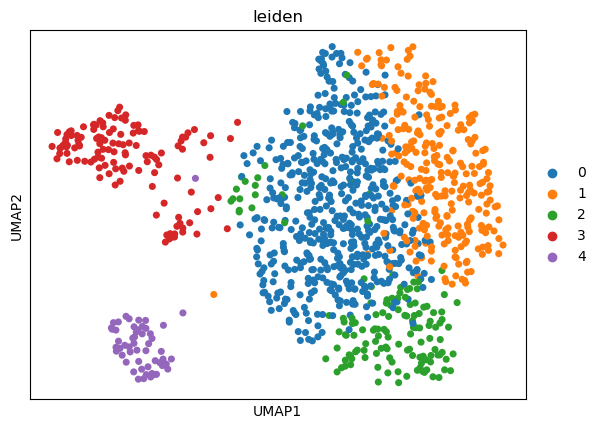

In [43]:
# Plot umap with leiden
sc.pl.umap(adata, color="leiden")

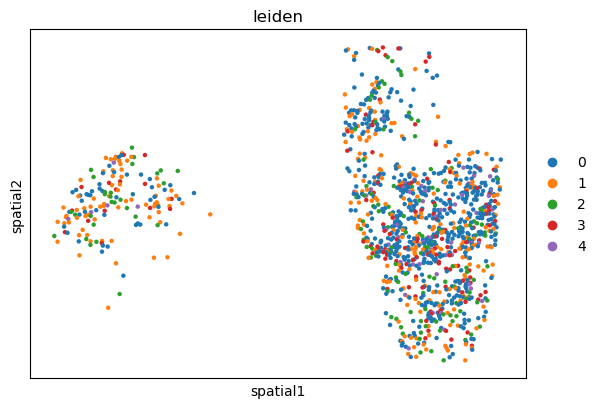

In [44]:
# Spatial plot
sc.pl.spatial(adata, spot_size=50, color="leiden")

In [45]:
# Extract Leiden cluster information from the adata object
leiden_clusters = adata.obs['leiden'].to_dict()

leiden_clusters = {int(k): int(v) for k, v in leiden_clusters.items()}

# Map the Leiden cluster to the gdf using the cell ID (index) in gdf
# Make sure the cell ID matches between gdf and adata (gdf.index and adata.obs.index should match)

# Assign -1 for cells not in adata (filtered out)
gdf['leiden'] = gdf.index.map(leiden_clusters).fillna(-1).astype(int)

In [46]:
# Define a color palette for clusters
cluster_colors = {
    -1: 'grey',  # Cells without clusters
    **{i: plt.cm.tab10(i) for i in range(len(set(adata.obs['leiden'])))}
}

# Map colors to the gdf
gdf['color'] = gdf['leiden'].map(cluster_colors)

## Create tmap file

In [49]:
import json

In [55]:
tmap = {
    "markerFiles": [
        {
            "path": f"./{spots_file}",
            "comment": "",
            "title": "",
            "hideSettings": True,
            "autoLoad": True,
            "uid": "GJUTQX",
            "name": f"{spots_file}",
            "expectedHeader": {
                "X": spots_x_col,
                "Y": spots_y_col,
                "gb_col": "gene_name",
                "gb_name": "null",
                "cb_col": "null",
                "scale_col": "null",
                "edges_col": "null",
                "sortby_col": "null",
                "pie_col": "null",
                "opacity_col": "null",
                "shape_col": "null",
                "collectionItem_col": "null",
                "z_order": "1",
                "cb_gr_dict": "",
                "cb_cmap": "",
                "scale_factor": "1",
                "coord_factor": "1",
                "pie_dict": "",
                "shape_fixed": "cross",
                "shape_gr_dict": "",
                "opacity": "1",
                "stroke_width": "2.5",
                "tooltip_fmt": "",
                "collectionItem_fixed": "0"
            },
            "expectedRadios": {
                "cb_col": False,
                "cb_gr": True,
                "cb_gr_rand": False,
                "cb_gr_dict": False,
                "cb_gr_key": True,
                "pie_check": False,
                "edges_check": False,
                "sortby_check": False,
                "sortby_desc_check": False,
                "scale_check": False,
                "shape_gr": True,
                "shape_gr_rand": True,
                "shape_gr_dict": False,
                "shape_col": False,
                "shape_fixed": False,
                "opacity_check": False,
                "_no_outline": False,
                "no_fill": False,
                "collectionItem_col": False,
                "collectionItem_fixed": True
            },
            "fromButton": 0
        }
    ],
    "schemaVersion": "1.3",
    "regions": {},
    "layers": [
        {
            "name": img_file,
            "tileSource": f"./{img_file}.dzi"
        }
    ],
    "filters": [
        "Saturation",
        "Brightness",
        "Contrast"
    ],
    "layerFilters": {
        "0": [
            {
                "value": "0",
                "name": "Saturation"
            },
            {
                "value": "0",
                "name": "Brightness"
            },
            {
                "value": "1",
                "name": "Contrast"
            }
        ]
    },
    "compositeMode": "source-over",
    "layerOpacities": {
        "0": "1"
    },
    "layerVisibilities": {
        "0": True
    }
}

In [78]:
import matplotlib.colors as mcolors

# Function to convert colors to HEX
def convert_to_hex(color):
    if isinstance(color, tuple):  # If it's an RGBA tuple
        return mcolors.to_hex(color)
    elif isinstance(color, str):  # If it's a named color
        return mcolors.CSS4_COLORS.get(color, color)  # Get hex, or return original if not found
    return color  # In case it's another format, return as is

# Apply function to 'color' column
gdf['hex_color'] = gdf['color'].apply(convert_to_hex)

In [88]:
gdf.leiden.value_counts()

leiden
-1    2688
 0     563
 1     273
 2     141
 3     127
 4      54
Name: count, dtype: int64

In [89]:
def extract_polygon_data(gdf):
    output_dict = {}
    
    for idx, row in gdf.iterrows():
        geometry = row.geometry  # Get polygon geometry
        region_name = f"Cell_{idx+1}"  # Generate region name
        
        # Extract polygon coordinates and format them
        global_points = []
        if geometry.geom_type == "Polygon":
            coords = list(geometry.exterior.coords)
            formatted_coords = [{"x": x, "y": y} for x, y in coords]
            global_points.append([formatted_coords])
        elif geometry.geom_type == "MultiPolygon":
            for poly in geometry.geoms:
                coords = list(poly.exterior.coords)
                formatted_coords = [{"x": x, "y": y} for x, y in coords]
                global_points.append([formatted_coords])

        # Compute bounding box
        bounds = geometry.bounds  # (minx, miny, maxx, maxy)
        _gxmin, _gymin, _gxmax, _gymax = bounds

        # Construct dictionary entry
        region_id = f"Region_geoJSON_{idx}"
        output_dict[region_id] = {
            "id": region_id,
            "globalPoints": global_points,
            "regionName": region_name,
            "regionClass": f"leiden_{row.leiden}",
            "barcodeHistogram": [],
            "visibility": True,
            "collectionIndex": 0,
            "len": 1,
            "polycolor": row.hex_color,
            "_gxmin": _gxmin,
            "_gxmax": _gxmax,
            "_gymin": _gymin,
            "_gymax": _gymax,
            "associatedPoints": [],
            "properties": {}
        }

    return output_dict

In [90]:
# Create a polygon dictionary
gdf_dict = extract_polygon_data(gdf)
# Assign the dictionary to the 'regions' key in the tmap
tmap["regions"] = gdf_dict

In [92]:
# Save the dict as a tmap file in a json format
with open(f"{base_path}/{experiment}.tmap", "w") as f:
    json.dump(tmap, f, indent=4)

In [93]:
## Save the tmap as a JSON file

import zipfile
import os

# List of file paths
file_paths = [
    f"{base_path}/{experiment}.tmap",
    f"{base_path}/{spots_file}",
    f"{base_path}/{segmentation_file}",
    f"{base_path}/{img_file}"
]

# Define the output ZIP file
zip_filename = f"{base_path}/{experiment}.zip"

# Create the ZIP file
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in file_paths:
        if os.path.exists(file):  # Ensure the file exists before adding
            zipf.write(file, os.path.basename(file))  # Add file with its name
        else:
            print(f"File not found: {file}")

print(f"ZIP file created at: {zip_filename}")

ZIP file created at: ../data/20240925CA-01//20240925CA-01.zip
